# Activity 1: Multiple Linear Regression – Predicting Hourly Traffic Volume

In [1]:
import warnings; warnings.filterwarnings('ignore')
import sys, sklearn, statsmodels
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)
print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__)

Python 3.13.5 | pandas 2.2.3 | scikit-learn 1.6.1


In [2]:
raw = pd.read_csv('Metro_Interstate_Traffic_Volume.csv.gz')
print('File type: CSV (gzip) | rows, columns:', raw.shape)
raw.head()

File type: CSV (gzip) | rows, columns: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [4]:
raw.info()
print()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB



In [5]:
raw.describe().round(2)

,temp,rain_1h,snow_1h,clouds_all,traffic_volume
count,48204.00,48204.00,48204.00,48204.00,48204.00
mean,281.21,0.33,0.00,49.36,3259.82
std,13.34,44.79,0.01,39.02,1986.86
min,0.00,0.00,0.00,0.00,0.00
25%,272.16,0.00,0.00,1.00,1193.00
50%,282.45,0.00,0.00,64.00,3380.00
75%,291.81,0.00,0.00,90.00,4933.00
max,310.07,9831.30,0.51,100.00,7280.00


In [6]:
df = raw.copy()
df['date_time'] = pd.to_datetime(df['date_time'])
print('Fully duplicated rows            :', df.duplicated().sum())
print('Repeated timestamps              :', df['date_time'].duplicated().sum(), '(same hour appears more than once)')
print('Temperature == 0 K rows          :', (df['temp'] == 0).sum())
print('Largest rain_1h values (mm)      :', df['rain_1h'].nlargest(3).values)
print('Traffic volume == 0 rows         :', (df['traffic_volume'] == 0).sum())
print('Non-blank holiday rows           :', df['holiday'].notna().sum())
print('Longest gap between observations :', df['date_time'].sort_values().diff().max())

Fully duplicated rows            : 17
Repeated timestamps              : 7629 (same hour appears more than once)
Temperature == 0 K rows          : 10
Largest rain_1h values (mm)      : [9831.3    55.63   44.45]
Traffic volume == 0 rows         : 2
Non-blank holiday rows           : 61
Longest gap between observations : 307 days 19:00:00


In [7]:
holiday_dates = set(df.loc[df['holiday'].notna(), 'date_time'].dt.date)

df = (df.drop_duplicates(subset='date_time', keep='first')
        .query('temp > 200 and rain_1h < 1000 and traffic_volume > 0')
        .sort_values('date_time').reset_index(drop=True))

df['temp_C']     = df['temp'] - 273.15                                  # Kelvin -> Celsius (easier to interpret)
df['hour']       = df['date_time'].dt.hour
df['is_weekend'] = (df['date_time'].dt.dayofweek >= 5).astype(int)
df['is_holiday'] = df['date_time'].dt.date.map(lambda d: int(d in holiday_dates))

print('Rows after cleaning:', len(df), '(removed', len(raw) - len(df), ')')
print('Hours flagged as holiday:', df['is_holiday'].sum())
print('Rows with snow_1h > 0   :', (df['snow_1h'] > 0).sum(), 'of', len(df), '-> snow_1h dropped (31 non-zero values is too few to estimate a reliable coefficient)')

Rows after cleaning: 40562 (removed 7642 )
Hours flagged as holiday: 1203
Rows with snow_1h > 0   : 31 of 40562 -> snow_1h dropped (31 non-zero values is too few to estimate a reliable coefficient)


In [8]:
features = ['temp_C', 'rain_1h', 'clouds_all', 'hour', 'is_weekend', 'is_holiday']
target = 'traffic_volume'
why = pd.DataFrame({
    'Feature': features,
    'Unit': ['degrees Celsius', 'mm in the last hour', '% cloud cover', 'hour of day (0-23)', '0/1', '0/1'],
    'Why it may influence traffic': [
        'Mild weather encourages more driving',
        'Rain slows or reduces trips',
        'Proxy for general weather',
        'Rush-hour and daily commute pattern',
        'Fewer commuters on weekends',
        'Fewer commuters on public holidays']})
why

,Feature,Unit,Why it may influence traffic
0,temp_C,degrees Celsius,Mild weather encourages more driving
1,rain_1h,mm in the last hour,Rain slows or reduces trips
2,clouds_all,% cloud cover,Proxy for general weather
3,hour,hour of day (0-23),Rush-hour and daily commute pattern
4,is_weekend,0/1,Fewer commuters on weekends
5,is_holiday,0/1,Fewer commuters on public holidays


In [9]:
df[features + [target]].describe().round(2)

,temp_C,rain_1h,clouds_all,hour,is_weekend,is_holiday,traffic_volume
count,40562.00,40562.00,40562.00,40562.00,40562.00,40562.00,40562.00
mean,8.23,0.08,44.21,11.52,0.29,0.03,3291.24
std,13.09,0.77,38.68,6.95,0.45,0.17,1984.55
min,-29.76,0.00,0.00,0.00,0.00,0.00,1.00
25%,-1.30,0.00,1.00,5.00,0.00,0.00,1250.00
50%,9.72,0.00,40.00,12.00,0.00,0.00,3429.00
75%,19.13,0.00,90.00,18.00,1.00,0.00,4952.00
max,36.92,55.63,100.00,23.00,1.00,1.00,7280.00


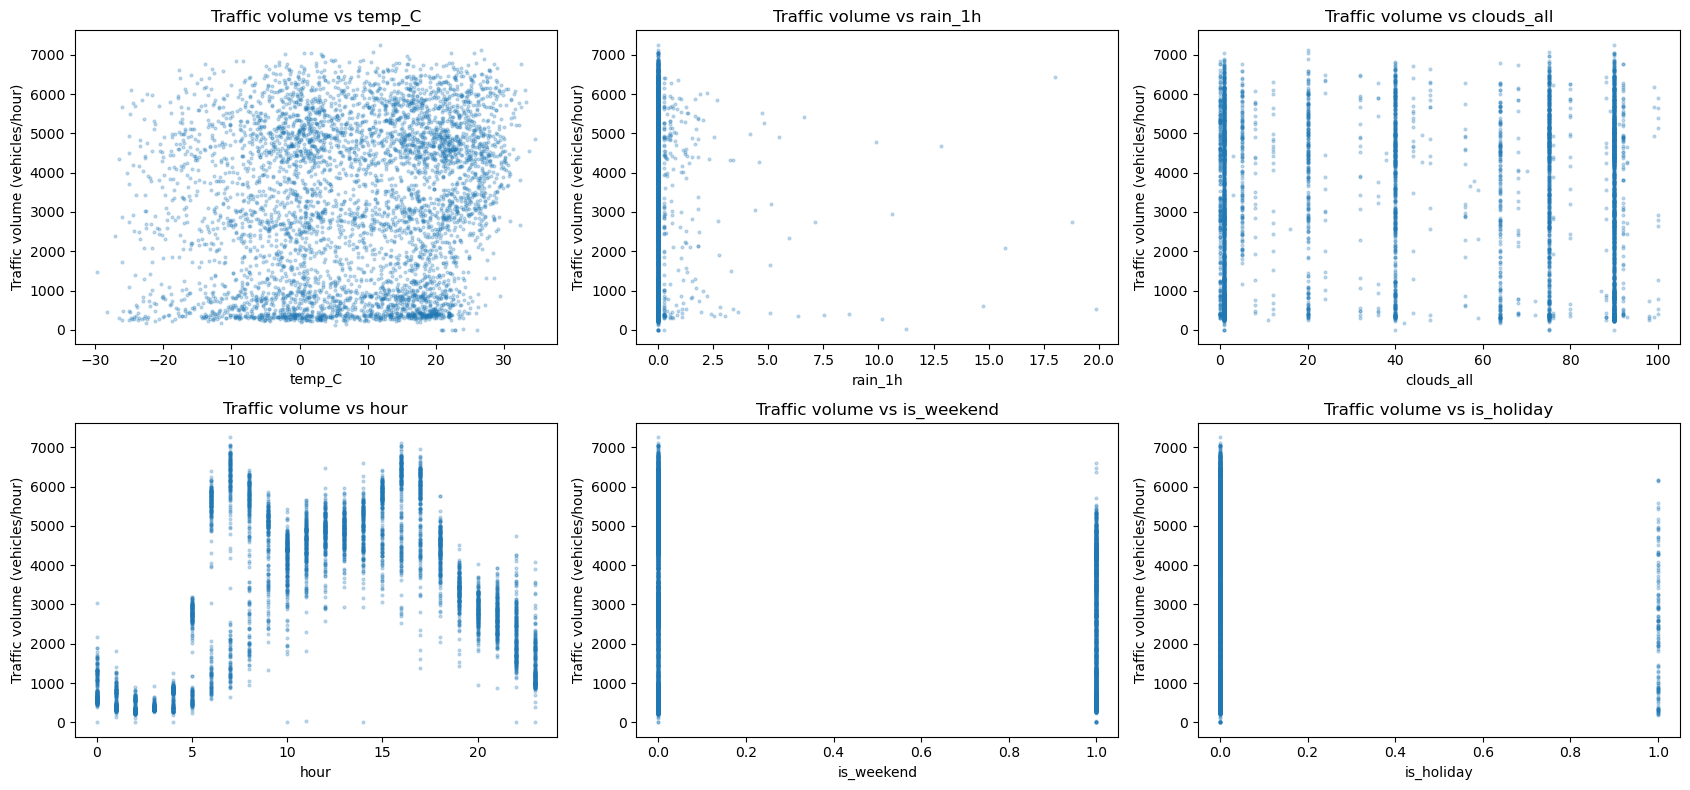

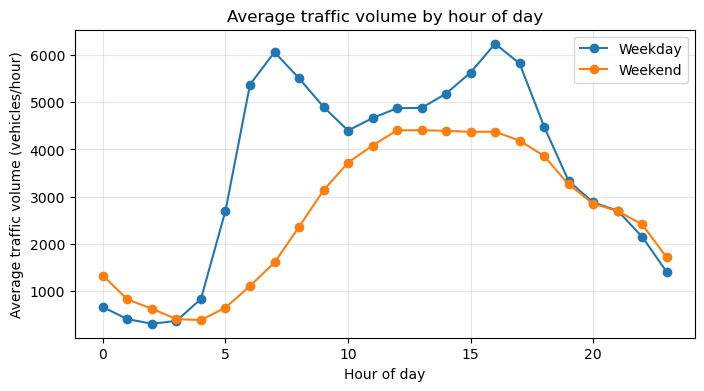

In [10]:
sample = df.sample(5000, random_state=SEED)   # 5,000 random points keeps the plots readable
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, f in zip(axes.ravel(), features):
    ax.scatter(sample[f], sample[target], s=4, alpha=.25)
    ax.set_title(f'Traffic volume vs {f}'); ax.set_xlabel(f); ax.set_ylabel('Traffic volume (vehicles/hour)')
plt.tight_layout(); plt.show()

hourly = df.groupby(['hour', 'is_weekend'])[target].mean().unstack()
hourly.columns = ['Weekday', 'Weekend']
hourly.plot(figsize=(8, 4), marker='o'); plt.title('Average traffic volume by hour of day')
plt.xlabel('Hour of day'); plt.ylabel('Average traffic volume (vehicles/hour)'); plt.grid(alpha=.3); plt.show()

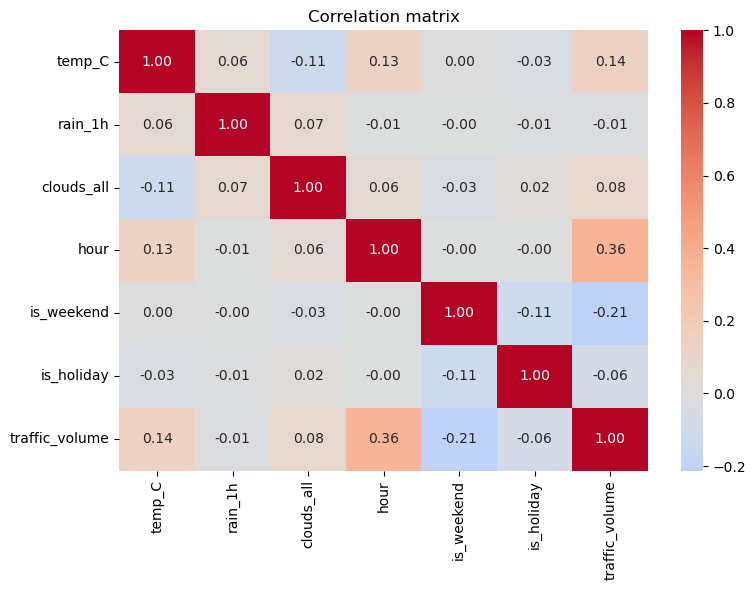

hour          0.355
is_weekend   -0.212
temp_C        0.139
clouds_all    0.078
is_holiday   -0.065
rain_1h      -0.013
Name: traffic_volume, dtype: float64

In [11]:
corr = df[features + [target]].corr()
plt.figure(figsize=(8, 6)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix'); plt.tight_layout(); plt.show()
corr[target].drop(target).sort_values(key=abs, ascending=False).round(3)

In [12]:
np.set_printoptions(precision=4, suppress=True, linewidth=120)
small = df.sample(6, random_state=7).sort_values('date_time')[['date_time', 'hour', 'temp_C', 'traffic_volume']].reset_index(drop=True)
small['temp_C'] = small['temp_C'].round(1)
print('Step 1 – the 6 chosen observations'); print(small.to_string()); print()

x1 = small['hour'].values.astype(float); x2 = small['temp_C'].values.astype(float); yv = small['traffic_volume'].values.astype(float)
X = np.column_stack([np.ones(len(small)), x1, x2])
print('Step 2 – design matrix X (columns: 1, x1 = hour, x2 = temp_C)'); print(X)
print('\n      target vector y'); print(yv)

XtX = X.T @ X
Xty = X.T @ yv
print('\nStep 3 – X^T X'); print(XtX)
print('\n         X^T y'); print(Xty)

Step 1 – the 6 chosen observations
            date_time  hour  temp_C  traffic_volume
0 2012-10-08 19:00:00    19     8.8            3069
1 2016-05-08 17:00:00    17    22.3            4420
2 2016-10-03 11:00:00    11    19.4            4277
3 2016-10-07 06:00:00     6     4.2            5528
4 2017-02-20 08:00:00     8    13.7            4929
5 2018-06-29 00:00:00     0    25.0             841

Step 2 – design matrix X (columns: 1, x1 = hour, x2 = temp_C)
[[ 1.  19.   8.8]
 [ 1.  17.  22.3]
 [ 1.  11.  19.4]
 [ 1.   6.   4.2]
 [ 1.   8.  13.7]
 [ 1.   0.  25. ]]

      target vector y
[3069. 4420. 4277. 5528. 4929.  841.]

Step 3 – X^T X
[[   6.     61.     93.4 ]
 [  61.    871.    894.5 ]
 [  93.4   894.5  1781.42]]

         X^T y
[ 23064.  253098.  320316.9]


In [13]:
det = np.linalg.det(XtX)
XtX_inv = np.linalg.inv(XtX)
print('Step 4 – determinant of X^T X = %.4f' % det)
print('\n         inverse (X^T X)^-1'); print(XtX_inv)

b = XtX_inv @ Xty
print('\nStep 5 – solve b = (X^T X)^-1 X^T y')
print('   b0 (intercept) = %.3f' % b[0]); print('   b1 (hour)      = %.3f' % b[1]); print('   b2 (temp_C)    = %.3f' % b[2])
print('\nCheck: (X^T X) b equals X^T y ?', np.allclose(XtX @ b, Xty))

print('\nStep 6 – fitted equation for the sample:  y = %.2f + %.2f*hour + %.2f*temp_C' % (b[0], b[1], b[2]))
i = 2
y_hat = b[0] + b[1] * x1[i] + b[2] * x2[i]
print(f'Prediction for observation {i + 1} (hour={x1[i]:.0f}, temp={x2[i]:.1f} C): {y_hat:.1f}')
print(f'Actual = {yv[i]:.0f} | residual = actual - predicted = {yv[i] - y_hat:.1f}')

Step 4 – determinant of X^T X = 474683.4400

         inverse (X^T X)^-1
[[ 1.5831 -0.0529 -0.0564]
 [-0.0529  0.0041  0.0007]
 [-0.0564  0.0007  0.0032]]

Step 5 – solve b = (X^T X)^-1 X^T y
   b0 (intercept) = 5043.544
   b1 (hour)      = 50.107
   b2 (temp_C)    = -109.784

Check: (X^T X) b equals X^T y ? True

Step 6 – fitted equation for the sample:  y = 5043.54 + 50.11*hour + -109.78*temp_C
Prediction for observation 3 (hour=11, temp=19.4 C): 3464.9
Actual = 4277 | residual = actual - predicted = 812.1


In [14]:
split = int(len(df) * 0.8)
train, test = df.iloc[:split].copy(), df.iloc[split:].copy()
print('Training set:', len(train), 'rows |', train['date_time'].min().date(), '->', train['date_time'].max().date())
print('Testing set :', len(test),  'rows |', test['date_time'].min().date(), '->', test['date_time'].max().date())
print('Train mean traffic: %.0f | Test mean traffic: %.0f' % (train[target].mean(), test[target].mean()))

Training set: 32449 rows | 2012-10-02 -> 2017-10-26
Testing set : 8113 rows | 2017-10-26 -> 2018-09-30
Train mean traffic: 3287 | Test mean traffic: 3309


In [15]:
def evaluate(y_true, y_pred, k):
    n = len(y_true); r2 = r2_score(y_true, y_pred)
    return {'MAE': mean_absolute_error(y_true, y_pred), 'MSE': mean_squared_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)), 'R2': r2,
            'Adj R2': 1 - (1 - r2) * (n - 1) / (n - k - 1)}

ytr, yte = train[target], test[target]

pred_mean = np.full(len(test), ytr.mean())
res_mean = evaluate(yte, pred_mean, 0)

best_feat = train[features + [target]].corr()[target].drop(target).abs().idxmax()
single = LinearRegression().fit(train[[best_feat]], ytr)
res_single = evaluate(yte, single.predict(test[[best_feat]]), 1)

print('Most correlated feature (training data):', best_feat)
print('Single-feature model:  traffic = %.1f + %.2f * %s' % (single.intercept_, single.coef_[0], best_feat))
print('Test R2 of single-feature model: %.3f' % res_single['R2'])

Most correlated feature (training data): hour
Single-feature model:  traffic = 2122.2 + 101.15 * hour
Test R2 of single-feature model: 0.130


In [16]:
multi = LinearRegression().fit(train[features], ytr)
pred_multi = multi.predict(test[features])
res_multi = evaluate(yte, pred_multi, len(features))

print('Intercept b0 = %.2f' % multi.intercept_)
coef_table = pd.DataFrame({'feature': features, 'coefficient': multi.coef_}).set_index('feature')
print(coef_table.round(3))

Intercept b0 = 2207.95
            coefficient
feature                
temp_C           17.015
rain_1h         -58.344
clouds_all        3.111
hour             96.210
is_weekend     -974.229
is_holiday    -1008.966


In [17]:
check = LinearRegression().fit(small[['hour', 'temp_C']], small['traffic_volume'])
print('Hand calculation : b0 = %.3f, b1 = %.3f, b2 = %.3f' % (b[0], b[1], b[2]))
print('Library (sklearn): b0 = %.3f, b1 = %.3f, b2 = %.3f' % (check.intercept_, check.coef_[0], check.coef_[1]))
print('Same result?', np.allclose([b[0], b[1], b[2]], [check.intercept_, *check.coef_]))

Hand calculation : b0 = 5043.544, b1 = 50.107, b2 = -109.784
Library (sklearn): b0 = 5043.544, b1 = 50.107, b2 = -109.784
Same result? True


In [18]:
eq = ' '.join(f'{c:+.2f}*{f}' for f, c in zip(features, multi.coef_))
print('Fitted equation (training data):')
print(f'traffic_volume = {multi.intercept_:.2f} {eq}')

Fitted equation (training data):
traffic_volume = 2207.95 +17.02*temp_C -58.34*rain_1h +3.11*clouds_all +96.21*hour -974.23*is_weekend -1008.97*is_holiday


In [19]:
units = {'temp_C': 'per +1 degree Celsius', 'rain_1h': 'per +1 mm of rain in the last hour', 'clouds_all': 'per +1 % of cloud cover',
         'hour': 'per +1 hour later in the day', 'is_weekend': 'weekend instead of weekday', 'is_holiday': 'holiday instead of normal day'}
for f, c in zip(features, multi.coef_):
    print(f'{f:11s}: {c:+8.2f} vehicles/hour {units[f]} (other features held constant)')

temp_C     :   +17.02 vehicles/hour per +1 degree Celsius (other features held constant)
rain_1h    :   -58.34 vehicles/hour per +1 mm of rain in the last hour (other features held constant)
clouds_all :    +3.11 vehicles/hour per +1 % of cloud cover (other features held constant)
hour       :   +96.21 vehicles/hour per +1 hour later in the day (other features held constant)
is_weekend :  -974.23 vehicles/hour weekend instead of weekday (other features held constant)
is_holiday : -1008.97 vehicles/hour holiday instead of normal day (other features held constant)


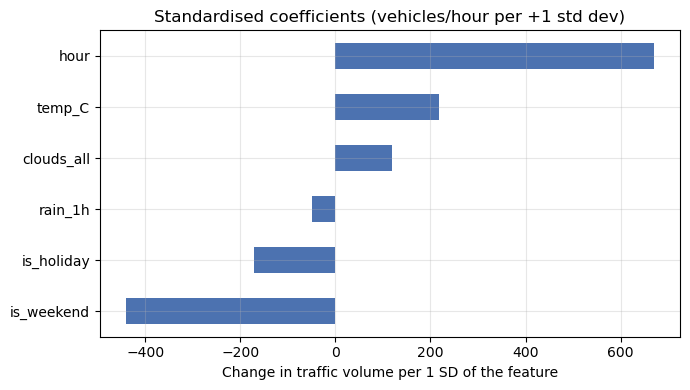

hour          669.3
is_weekend   -439.8
temp_C        218.3
is_holiday   -171.3
clouds_all    120.0
rain_1h       -49.0
dtype: float64

In [20]:
sc = StandardScaler().fit(train[features])
multi_std = LinearRegression().fit(sc.transform(train[features]), ytr)
std_coef = pd.Series(multi_std.coef_, index=features).sort_values(key=abs, ascending=False)
plt.figure(figsize=(7, 4)); std_coef.sort_values().plot.barh(color='#4C72B0')
plt.title('Standardised coefficients (vehicles/hour per +1 std dev)'); plt.xlabel('Change in traffic volume per 1 SD of the feature'); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
std_coef.round(1)

In [21]:
cmp = pd.DataFrame({'date_time': test['date_time'].values, 'actual': yte.values, 'predicted': pred_multi.round(0)})
cmp['difference'] = (cmp['actual'] - cmp['predicted']).round(0)
cmp.sample(12, random_state=SEED).sort_values('date_time').reset_index(drop=True)

,date_time,actual,predicted,difference
0,2017-11-14 20:00:00,2778,4515.0,-1737.0
1,2018-01-12 18:00:00,4677,3658.0,1019.0
2,2018-01-25 02:00:00,265,2611.0,-2346.0
3,2018-03-07 23:00:00,1352,4260.0,-2908.0
4,2018-04-01 12:00:00,3964,2304.0,1660.0
5,2018-04-11 18:00:00,4955,4349.0,606.0
6,2018-04-24 13:00:00,4960,3858.0,1102.0
7,2018-06-05 21:00:00,2754,4630.0,-1876.0
8,2018-06-08 09:00:00,5011,3682.0,1329.0
9,2018-09-20 21:00:00,3497,4643.0,-1146.0


In [22]:
table = pd.DataFrame({'Mean baseline': res_mean, f'Single feature ({best_feat})': res_single, 'Multiple (6 features)': res_multi}).T.round(3)
table

,MAE,MSE,RMSE,R2,Adj R2
Mean baseline,1724.112,3882301.709,1970.356,-0.000,-0.000
Single feature (hour),1637.451,3378256.443,1838.003,0.130,0.130
Multiple (6 features),1550.671,3131860.537,1769.706,0.193,0.193


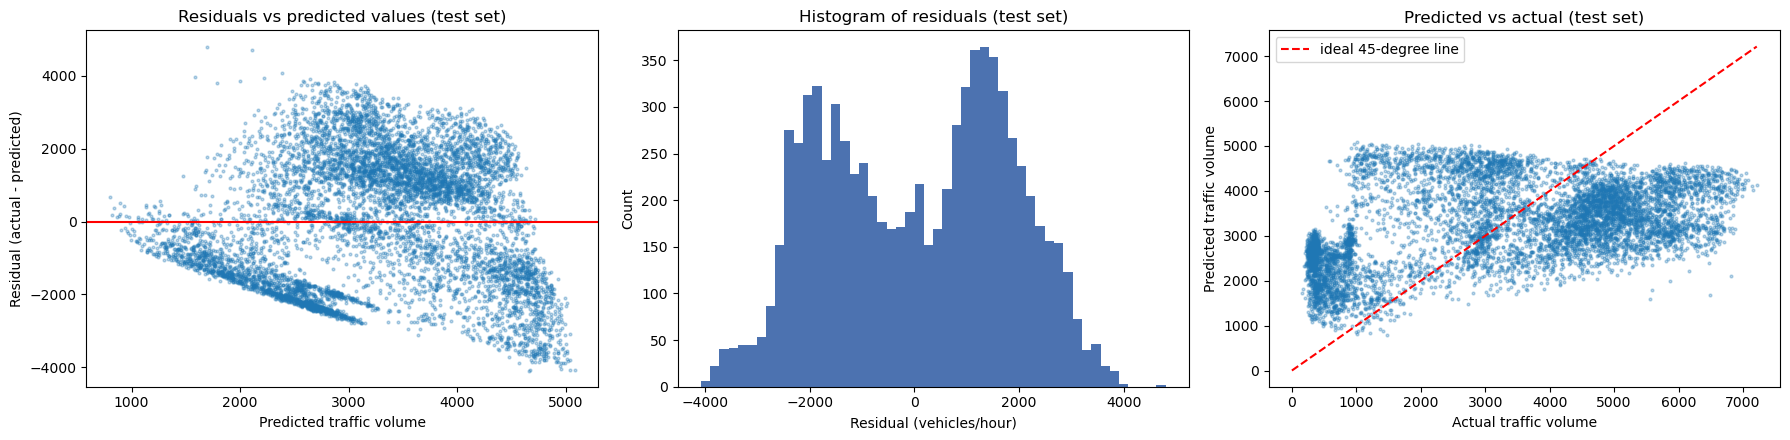

Mean residual: 52.2 | Durbin-Watson: 0.24 (2 = no autocorrelation, near 0 = strong positive autocorrelation)


In [23]:
resid = yte.values - pred_multi
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].scatter(pred_multi, resid, s=4, alpha=.3); ax[0].axhline(0, color='r')
ax[0].set_title('Residuals vs predicted values (test set)'); ax[0].set_xlabel('Predicted traffic volume'); ax[0].set_ylabel('Residual (actual - predicted)')
ax[1].hist(resid, bins=50, color='#4C72B0'); ax[1].set_title('Histogram of residuals (test set)'); ax[1].set_xlabel('Residual (vehicles/hour)'); ax[1].set_ylabel('Count')
ax[2].scatter(yte, pred_multi, s=4, alpha=.3); lim = [0, max(yte.max(), pred_multi.max())]; ax[2].plot(lim, lim, 'r--', label='ideal 45-degree line')
ax[2].set_title('Predicted vs actual (test set)'); ax[2].set_xlabel('Actual traffic volume'); ax[2].set_ylabel('Predicted traffic volume'); ax[2].legend()
plt.tight_layout(); plt.show()
print('Mean residual: %.1f | Durbin-Watson: %.2f (2 = no autocorrelation, near 0 = strong positive autocorrelation)' % (resid.mean(), durbin_watson(resid)))

In [24]:
Xc = sm.add_constant(train[features])
vif = pd.DataFrame({'feature': features, 'VIF': [variance_inflation_factor(Xc.values, i + 1) for i in range(len(features))]}).round(2)
print(vif.to_string(index=False))

   feature  VIF
    temp_C 1.05
   rain_1h 1.01
clouds_all 1.03
      hour 1.02
is_weekend 1.01
is_holiday 1.01


In [25]:
hour_dummies = pd.get_dummies(df['hour'], prefix='h', drop_first=True).astype(float)
df2 = pd.concat([df, hour_dummies], axis=1)
feat2 = ['temp_C', 'rain_1h', 'clouds_all', 'is_weekend', 'is_holiday'] + list(hour_dummies.columns)
train2, test2 = df2.iloc[:split], df2.iloc[split:]

multi2 = LinearRegression().fit(train2[feat2], train2[target])
pred_multi2 = multi2.predict(test2[feat2])
res_multi2 = evaluate(yte, pred_multi2, len(feat2))

final = pd.DataFrame({'Mean baseline': res_mean, f'Single feature ({best_feat})': res_single, 'Multiple (6 features)': res_multi,
                      'Multiple + hour-of-day dummies': res_multi2}).T.round(3)
final

,MAE,MSE,RMSE,R2,Adj R2
Mean baseline,1724.112,3882301.709,1970.356,-0.000,-0.000
Single feature (hour),1637.451,3378256.443,1838.003,0.130,0.130
Multiple (6 features),1550.671,3131860.537,1769.706,0.193,0.193
Multiple + hour-of-day dummies,588.115,629104.509,793.161,0.838,0.837


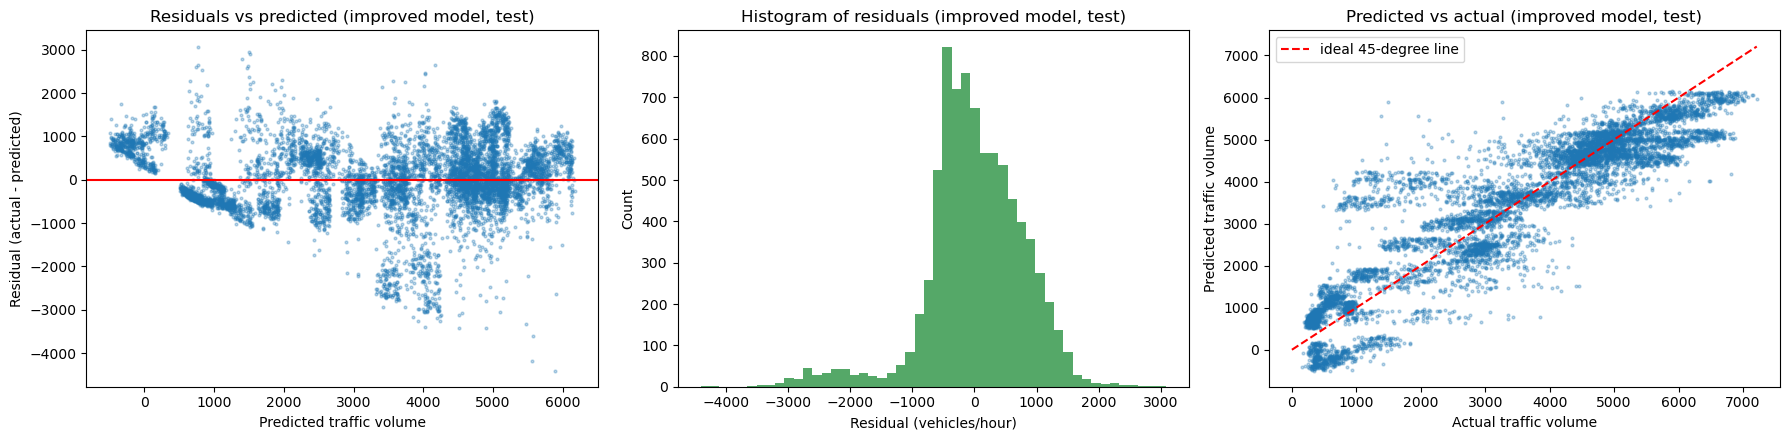

Durbin-Watson (improved model): 0.35


In [26]:
resid2 = yte.values - pred_multi2
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].scatter(pred_multi2, resid2, s=4, alpha=.3); ax[0].axhline(0, color='r'); ax[0].set_title('Residuals vs predicted (improved model, test)')
ax[0].set_xlabel('Predicted traffic volume'); ax[0].set_ylabel('Residual (actual - predicted)')
ax[1].hist(resid2, bins=50, color='#55A868'); ax[1].set_title('Histogram of residuals (improved model, test)'); ax[1].set_xlabel('Residual (vehicles/hour)'); ax[1].set_ylabel('Count')
ax[2].scatter(yte, pred_multi2, s=4, alpha=.3); ax[2].plot(lim, lim, 'r--', label='ideal 45-degree line'); ax[2].set_title('Predicted vs actual (improved model, test)')
ax[2].set_xlabel('Actual traffic volume'); ax[2].set_ylabel('Predicted traffic volume'); ax[2].legend()
plt.tight_layout(); plt.show()
print('Durbin-Watson (improved model): %.2f' % durbin_watson(resid2))

In [27]:
vif2 = pd.DataFrame({'feature': feat2, 'VIF': [variance_inflation_factor(sm.add_constant(train2[feat2]).values, i + 1) for i in range(len(feat2))]})
print('Max VIF in improved model: %.2f' % vif2['VIF'].max())

Max VIF in improved model: 1.92


In [28]:
print('Training ranges: temp_C %.1f to %.1f | rain_1h 0 to %.1f | clouds 0 to 100 | hour 0-23' % (train['temp_C'].min(), train['temp_C'].max(), train['rain_1h'].max()))
new = {'temp_C': 15.0, 'rain_1h': 0.0, 'clouds_all': 40, 'hour': 8, 'is_weekend': 0, 'is_holiday': 0}   # a mild, dry Tuesday at 8 am
x_new = pd.DataFrame([new])
p1 = multi.predict(x_new[features])[0]

x_new2 = pd.DataFrame([{**{k: v for k, v in new.items() if k != 'hour'}, **{c: 0.0 for c in hour_dummies.columns}}])
x_new2['h_8'] = 1.0
p2 = multi2.predict(x_new2[feat2])[0]

actual_8am = df[(df['hour'] == 8) & (df['is_weekend'] == 0) & (df['is_holiday'] == 0)]['traffic_volume'].mean()
print('New record:', new)
print(f'Prediction – 6-feature model            : {p1:,.0f} vehicles/hour')
print(f'Prediction – model with hour dummies    : {p2:,.0f} vehicles/hour')
print(f'(For reference, the historical average on weekday 8 am hours is {actual_8am:,.0f} vehicles/hour)')

Training ranges: temp_C -29.8 to 35.1 | rain_1h 0 to 55.6 | clouds 0 to 100 | hour 0-23
New record: {'temp_C': 15.0, 'rain_1h': 0.0, 'clouds_all': 40, 'hour': 8, 'is_weekend': 0, 'is_holiday': 0}
Prediction – 6-feature model            : 3,357 vehicles/hour
Prediction – model with hour dummies    : 4,991 vehicles/hour
(For reference, the historical average on weekday 8 am hours is 5,629 vehicles/hour)


## 16. Conclusion, limitations and ethics

**Summary.** Dataset: UCI Metro Interstate Traffic Volume (40,562 clean hourly rows). Target: `traffic_volume`. After cleaning impossible values and repeated timestamps, I fitted (i) the mean baseline (R² ≈ 0), (ii) a single-feature model on `hour` (test R² ≈ 0.13), (iii) a multiple linear regression on six features (test R² ≈ 0.19, RMSE ≈ 1,770), and (iv) the same linear model with hour-of-day dummies (test R² ≈ 0.84, RMSE ≈ 790). The extra features helped, but the biggest gain came from representing the **shape** of the effect of hour correctly, not from adding more columns.

**Adding more features does not always improve a model; features can overlap in the information they carry** (the weather text columns were dropped for that reason), **and a linear model can miss non-linear effects and other factors**, as the `hour` example shows.

**Limitations.**
- Hourly data is autocorrelated, so independence is violated: coefficient p-values and confidence intervals should not be trusted; predictions are still usable but should be checked with proper time-series methods.
- Accidents, roadworks, events, seasons and trends over the years are missing.
- One road segment in one city and a single seven-year period: do not generalise to other roads or countries.
- Held-out period is a different time of year/years from training, which is realistic but stricter.

**What this model should NOT be used for.** It should not be used for real-time control, safety-critical decisions or for roads other than this segment. Use it only as an average-pattern planning aid.

**Ethics.** The data are public traffic counts and weather with no personal information. Wrong forecasts could lead to poor staffing or signal planning, affecting commuters, so predictions should be treated as estimates and reviewed by people.